# Milestone 1: Data Understanding, Defect Exploration and Metrics

### Objective
The task is to detect surface anomalies in industrial images and mark, for each of four defect categories, exactly which pixels are affected (semantic segmentation). Before building any model, this notebook studies the data, the mask format and the evaluation metric, so that every later modelling decision is backed by evidence from the training set.

---

## 0. Environment and Configuration

Imports, constants and a fixed random seed are defined once so that the notebook is reproducible.

In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
IMG_H, IMG_W = 128, 800
DEFECT_TYPES = ["defect_a", "defect_b", "defect_c", "defect_d"]

print(f"torch {torch.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print("GPU available:", torch.cuda.is_available())

torch 2.11.0+cu128 | pandas 2.3.3 | numpy 2.1.3
GPU available: True


## 1. Dataset Overview

**Objective:** verify the structure and quality of the provided files before analysis.

In [2]:
print("Files in the competition directory:")
for p in sorted(DATA_DIR.iterdir()):
    print(" -", p.name)

Files in the competition directory:
 - sample_submission.csv
 - test
 - train
 - train.csv


In [3]:
train = pd.read_csv(DATA_DIR / "train.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

n_images = train.image_id.nunique()
print(f"train.csv: {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"Unique training images: {n_images:,}")
print(f"Rows per image: {len(train) / n_images:.1f}")
print("Image sizes (width, height):", train[["width", "height"]].drop_duplicates().values.tolist())

print("\nMissing values per column:")
print(train.isna().sum())
print("Duplicate (image_id, defect_type) pairs:", train.duplicated(["image_id", "defect_type"]).sum())

n_test_images = sample_sub.image_id.nunique()
print(f"\nsample_submission.csv: {len(sample_sub):,} rows covering {n_test_images:,} test images")
train.head(8)

train.csv: 45,572 rows x 5 columns
Unique training images: 11,393
Rows per image: 4.0
Image sizes (width, height): [[800, 128]]

Missing values per column:
image_id           0
defect_type        0
mask_rle       38371
width              0
height             0
dtype: int64
Duplicate (image_id, defect_type) pairs: 0

sample_submission.csv: 12,000 rows covering 3,000 test images


,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,NaN,800,128
2,4S22I7SA34,defect_c,NaN,800,128
3,4S22I7SA34,defect_d,NaN,800,128
4,DZ899111OE,defect_a,NaN,800,128
5,DZ899111OE,defect_b,NaN,800,128
6,DZ899111OE,defect_c,NaN,800,128
7,DZ899111OE,defect_d,NaN,800,128


### Observations
- The table is in **long format**: every image has exactly one row per defect type, so `rows = images x 4`.
- All images have the same size, 800 x 128 pixels (width x height), a very wide strip with aspect ratio 6.25 : 1.
- Missing values occur only in `mask_rle`. A missing mask is not corrupt data: it encodes *no defect of this type in this image*.
- There are no duplicate (image, defect) pairs, so no cleaning is required.

---

## Q1. Global Class Distribution and Clean-Image Mass

**Objective:** quantify how sparse the defects are by (a) counting positive samples per defect class and (b) counting completely clean images, i.e. images whose four masks are all empty.

In [4]:

train["has_defect"] = train.mask_rle.notna() & (train.mask_rle.astype(str).str.strip() != "")
positives = train[train.has_defect]

class_counts = positives.defect_type.value_counts().reindex(DEFECT_TYPES)
class_table = pd.DataFrame({
    "positive_images": class_counts,
    "share_of_images_%": (100 * class_counts / n_images).round(2),
})
display(class_table)

n_defective = positives.image_id.nunique()
n_clean = n_images - n_defective
print(f"Images with at least one defect: {n_defective:,}")
print(f"Completely clean images:         {n_clean:,}  ({100 * n_clean / n_images:.1f}% of all images)")

most_frequent = class_counts.idxmax()
q1_answer = int(class_counts.max() + n_clean)
print(f"\nMost frequent class: {most_frequent} ({class_counts.max():,} positives)")
print(f"Q1 answer = {class_counts.max():,} + {n_clean:,} = {q1_answer:,}")

,positive_images,share_of_images_%
defect_type,,
defect_a,1081,9.49
defect_b,313,2.75
defect_c,4100,35.99
defect_d,1707,14.98


Images with at least one defect: 5,877
Completely clean images:         5,516  (48.4% of all images)

Most frequent class: defect_c (4,100 positives)
Q1 answer = 4,100 + 5,516 = 9,616


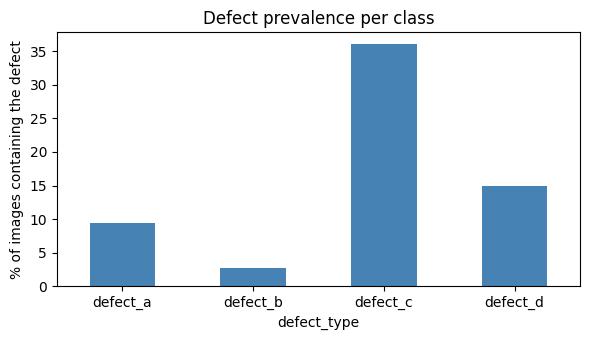

In [5]:
class_table["share_of_images_%"].plot(kind="bar", color="steelblue", figsize=(6, 3.5))
plt.ylabel("% of images containing the defect")
plt.title("Defect prevalence per class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation
- The classes are strongly imbalanced: one class (`defect_c`) is clearly the most common, while `defect_b` is the rarest and has very few training examples. A rare class gives the model little to learn from and makes validation estimates noisy.
- A large share of all images is completely clean. Most image-class pairs are therefore empty, so a trivial "predict nothing" model would look good under plain accuracy. This motivates Dice-based metrics, a loss that does not let the background dominate, and a validation split that preserves rare classes.

---

## Q2. Multi-Label Cardinality and Co-occurrence

**Objective:** measure how many defect classes appear together on the same image.

In [6]:
cardinality = (
    positives.groupby("image_id").defect_type.nunique()
    .reindex(train.image_id.unique(), fill_value=0)
)

dist = cardinality.value_counts().sort_index().rename("images")
display(dist.to_frame())

multi_label_ids = cardinality[cardinality > 1].index
q2_answer = len(multi_label_ids)
print(f"Images with strictly more than one defect class: {q2_answer:,}")
print(f"Share of defective images that are multi-label:   {100 * q2_answer / n_defective:.1f}%")

# Which pairs of classes appear together?
presence = (
    train.pivot(index="image_id", columns="defect_type", values="has_defect")[DEFECT_TYPES].astype(int)
)
cooc = presence.T.dot(presence)
display(cooc)

,images
defect_type,
0,5516
1,4679
2,1072
3,126


Images with strictly more than one defect class: 1,198
Share of defective images that are multi-label:   20.4%


defect_type,defect_a,defect_b,defect_c,defect_d
defect_type,,,,
defect_a,1081,42,310,234
defect_b,42,313,95,64
defect_c,310,95,4100,705
defect_d,234,64,705,1707


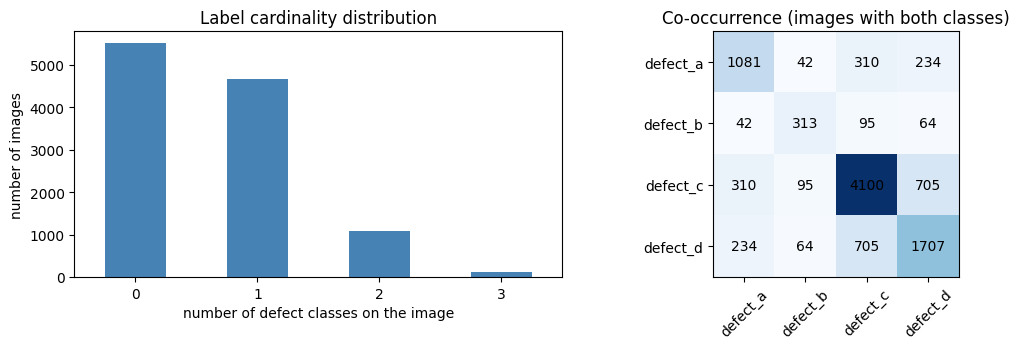

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
dist.plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_xlabel("number of defect classes on the image")
ax[0].set_ylabel("number of images")
ax[0].set_title("Label cardinality distribution")
ax[0].tick_params(axis="x", rotation=0)

im = ax[1].imshow(cooc.values, cmap="Blues")
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(DEFECT_TYPES, rotation=45)
ax[1].set_yticks(range(4)); ax[1].set_yticklabels(DEFECT_TYPES)
for i in range(4):
    for j in range(4):
        ax[1].text(j, i, int(cooc.values[i, j]), ha="center", va="center")
ax[1].set_title("Co-occurrence (images with both classes)")
plt.tight_layout()
plt.show()

### Interpretation
- The cardinality distribution peaks at 0 and 1; multi-label images are a minority of the defective images but are far from negligible, and no image carries all four defect types.
- Co-occurrence is not uniform: some class pairs appear together much more often than others, while `defect_b` rarely appears with anything.

---

## Q3. Spatial Mutual Exclusivity of Defect Masks

**Objective:** test whether any pixel is labelled with two or more defect classes at once, and use the result to justify the output-head design of the segmentation model.

In [8]:
def rle_decode(rle, shape=(IMG_H, IMG_W)):
    """Decode a 1-based, column-major RLE string into a binary (H, W) mask."""
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        tokens = [int(t) for t in rle.split()]
        starts = np.array(tokens[0::2]) - 1        
        ends = starts + np.array(tokens[1::2])      
        for s, e in zip(starts, ends):
            flat[max(s, 0):min(e, flat.size)] = 1 
    return flat.reshape(shape, order="F")


toy = rle_decode("3 4 10 2", shape=(4, 4))
print(toy)
print("foreground pixels:", toy.sum())

[[0 1 0 0]
 [0 1 1 0]
 [1 0 1 0]
 [1 0 0 0]]
foreground pixels: 6


In [9]:
multi_rows = positives[positives.image_id.isin(multi_label_ids)]

pair_overlap = np.zeros((4, 4), dtype=np.int64)   # sum over images of |M_i AND M_j|
pixels_with_2plus_labels = 0

for image_id, rows in multi_rows.groupby("image_id"):
    stack = np.zeros((4, IMG_H, IMG_W), dtype=np.uint8)
    for _, r in rows.iterrows():
        stack[DEFECT_TYPES.index(r.defect_type)] = rle_decode(r.mask_rle)

    for i in range(4):
        for j in range(4):
            pair_overlap[i, j] += int(np.logical_and(stack[i], stack[j]).sum())
    pixels_with_2plus_labels += int((stack.sum(axis=0) >= 2).sum())

overlap_df = pd.DataFrame(pair_overlap, index=DEFECT_TYPES, columns=DEFECT_TYPES)
print(f"Multi-label images audited: {multi_rows.image_id.nunique():,}")
print("\nPairwise overlap matrix (diagonal = total area of each class):")
display(overlap_df)

off_diagonal = int(np.triu(pair_overlap, k=1).sum())
print(f"Sum of off-diagonal pair overlaps (class i vs class j, i < j): {off_diagonal:,}")
print(f"Q3 answer: pixels carrying >= 2 defect labels = {pixels_with_2plus_labels:,}")

verdict = ("defect masks are spatially disjoint -> a background + 4-class softmax partition is consistent with the labels"
           if pixels_with_2plus_labels == 0 else
           "defect masks overlap -> a softmax head cannot represent the labels; use 4 independent sigmoids")
print("Verdict:", verdict)

Multi-label images audited: 1,198

Pairwise overlap matrix (diagonal = total area of each class):


,defect_a,defect_b,defect_c,defect_d
defect_a,271621,0,0,0
defect_b,0,103350,0,0
defect_c,0,0,3711253,0
defect_d,0,0,0,5986554


Sum of off-diagonal pair overlaps (class i vs class j, i < j): 0
Q3 answer: pixels carrying >= 2 defect labels = 0
Verdict: defect masks are spatially disjoint -> a background + 4-class softmax partition is consistent with the labels


### Interpretation
- The diagonal of the matrix holds each class's total area (a mask intersected with itself), so it is never zero for a class that has masks. Only the **off-diagonal** entries measure overlap between different classes.
- The audit total printed above is the number of pixels labelled by two or more classes. It differs from the sum of pairwise overlaps only when a pixel carries three labels (the pair sum would count it three times, the pixel count once).
- **Decision rule:** a total of zero means the ground truth is a strict spatial partition, so mutually exclusive classes (softmax with a background channel, K = 5) match the label structure; any positive total means the labels are genuinely multi-label at pixel level and independent sigmoid channels (K = 4) with a BCE-style loss are required.

---

## Q4. RLE Standards and the Boundary Edge Case

**Objective:** audit every non-empty RLE string for runs that extend past the canvas boundary and report how many rows are affected and the largest pixel index encountered.

In [10]:
CANVAS_PIXELS = IMG_H * IMG_W  

def run_bounds(rle):
    """Return (start indices, 1-based end indices) of every run in an RLE string."""
    tokens = [int(t) for t in rle.split()]
    starts, lengths = np.array(tokens[0::2]), np.array(tokens[1::2])
    return starts, starts + lengths - 1


audit = positives[["image_id", "defect_type", "mask_rle"]].copy()
bounds = audit.mask_rle.apply(run_bounds)
audit["min_start"] = bounds.apply(lambda b: b[0].min())
audit["max_end"] = bounds.apply(lambda b: b[1].max())

malformed = audit[audit.max_end > CANVAS_PIXELS]

print(f"Non-empty RLE rows inspected:               {len(audit):,}")
print(f"Smallest start index found:                 {audit.min_start.min():,} (must be >= 1)")
print(f"Rows with a run ending beyond {CANVAS_PIXELS:,}:      {len(malformed):,}")
print(f"Maximum pixel index encountered:            {audit.max_end.max():,}")
print(f"\nQ4 answer: {len(malformed)} rows, max index {audit.max_end.max()}")

Non-empty RLE rows inspected:               7,201
Smallest start index found:                 1 (must be >= 1)
Rows with a run ending beyond 102,400:      0
Maximum pixel index encountered:            102,400

Q4 answer: 0 rows, max index 102400


### Interpretation
- The audit reports the number of malformed rows and the highest index directly, so the answer is read from the data, not assumed.
- A maximum index equal to 102,400 means that the last pixel of the canvas is used but not exceeded; a larger value would indicate runs that spill over the boundary.

---

## Q5. Geometric Distortion and Anisotropic Aspect Ratio

**Objective:** quantify how much a standard "resize to a square" step distorts the 128 x 800 images, and show empirically what this does to ground-truth masks.

In [11]:
import cv2

H0, W0 = IMG_H, IMG_W
H_t, W_t = 256, 256

s_x = W_t / W0          
s_y = H_t / H0         
R = s_y / s_x           

print(f"s_x = {W_t}/{W0} = {s_x:.4f}")
print(f"s_y = {H_t}/{H0} = {s_y:.4f}")
print(f"R = s_y / s_x = {R:.4f}")
print(f"\nQ5 answer: {s_x:.2f}, {s_y:.2f}, {R:.2f}")

s_x = 256/800 = 0.3200
s_y = 256/128 = 2.0000
R = s_y / s_x = 6.2500

Q5 answer: 0.32, 2.00, 6.25


In [12]:
def roundtrip(mask):
    """Resize a binary mask to 256x256 (bilinear), threshold, resize back (nearest); return (IoU, recall)."""
    big = cv2.resize(mask.astype(np.float32), (W_t, H_t), interpolation=cv2.INTER_LINEAR)
    big = (big > 0.5).astype(np.uint8)
    back = cv2.resize(big, (W0, H0), interpolation=cv2.INTER_NEAREST)
    inter = np.logical_and(mask, back).sum()
    union = np.logical_or(mask, back).sum()
    return inter / union, inter / mask.sum()


rows = []
for defect in DEFECT_TYPES:
    cls_rows = positives[positives.defect_type == defect]
    sample = cls_rows.sample(min(300, len(cls_rows)), random_state=SEED)
    scores = np.array([roundtrip(rle_decode(rle)) for rle in sample.mask_rle])
    rows.append({"defect_type": defect, "masks_tested": len(sample),
                 "mean_IoU_after_roundtrip": scores[:, 0].mean(),
                 "mean_pixel_recall": scores[:, 1].mean()})

roundtrip_df = pd.DataFrame(rows).set_index("defect_type").round(3)
display(roundtrip_df)
worst = roundtrip_df.mean_IoU_after_roundtrip.idxmin()
print(f"Lowest round-trip IoU: {worst}")

,masks_tested,mean_IoU_after_roundtrip,mean_pixel_recall
defect_type,,,
defect_a,300,0.840,0.911
defect_b,300,0.777,0.878
defect_c,300,0.885,0.938
defect_d,300,0.957,0.978


Lowest round-trip IoU: defect_b


### Interpretation
- Resizing 128 x 800 to 256 x 256 stretches the height by `s_y` and compresses the width by `s_x`. The printed ratio `R` is large: for a square target it equals the source aspect ratio `W0 / H0`, i.e. the image is distorted by a factor of 6.25 between the two axes.
- The round trip shows the cost on real masks even for a *perfect* model: the mean IoU after resizing out and back is clearly below 1 for every class, and it is lowest for the class printed above, which contains the thinnest structures. This is irrecoverable information loss caused by the resize, not a modelling error.

---

## Q6. Photometric Invisibility and Defect Feature Types (Cohen's d)

**Objective:** measure, for each defect class, how well pixel brightness alone separates defect pixels from background, and identify which class is photometrically invisible.

In [13]:
from PIL import Image

IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
image_index = {p.stem: p for p in DATA_DIR.rglob("*") if p.suffix.lower() in IMAGE_EXTS}

train_ids = set(train.image_id)
print(f"Image files found: {len(image_index):,} | training ids with an image file: "
      f"{len(train_ids & set(image_index)):,} of {len(train_ids):,}")


def load_gray(image_id):
    """Load an image as float64 grey values with shape (128, 800)."""
    img = np.asarray(Image.open(image_index[image_id]).convert("L"))
    assert img.shape == (IMG_H, IMG_W), f"unexpected shape {img.shape} for {image_id}"
    return img.astype(np.float64)

Image files found: 14,393 | training ids with an image file: 11,393 of 11,393


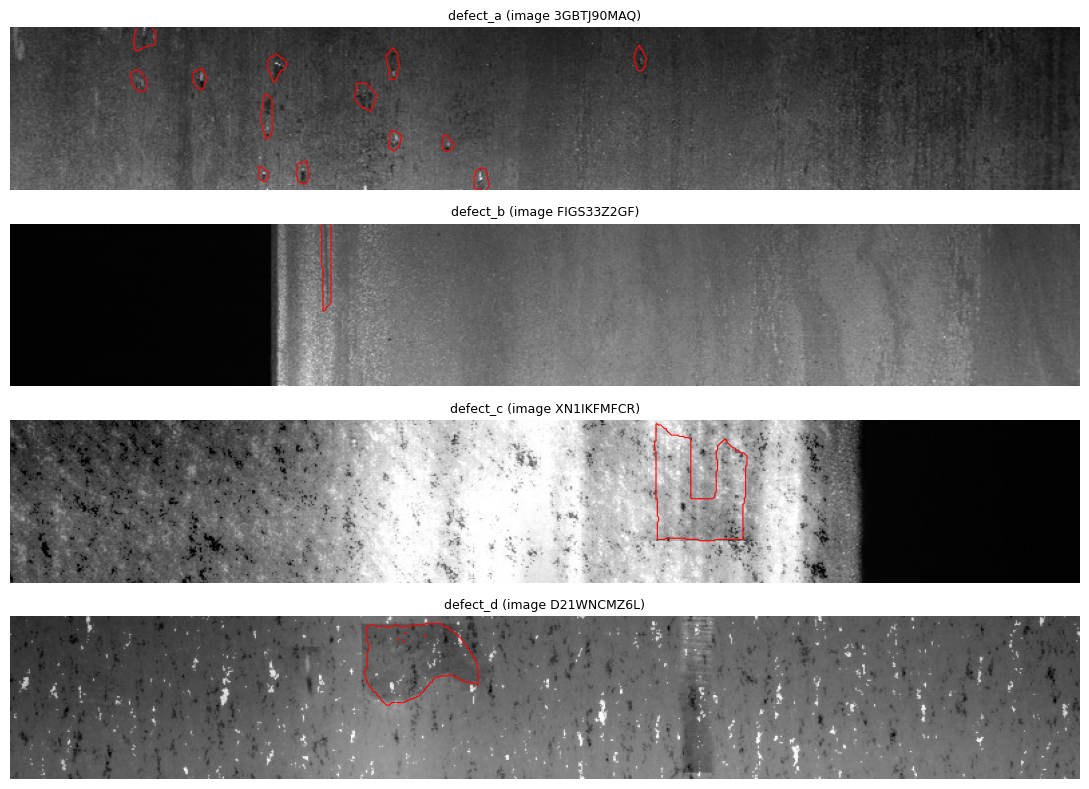

In [14]:
fig, axes = plt.subplots(4, 1, figsize=(11, 8))
for ax, defect in zip(axes, DEFECT_TYPES):
    row = positives[positives.defect_type == defect].sample(1, random_state=SEED).iloc[0]
    ax.imshow(load_gray(row.image_id), cmap="gray", aspect="auto")
    ax.contour(rle_decode(row.mask_rle), levels=[0.5], colors="red", linewidths=0.8)
    ax.set_title(f"{defect} (image {row.image_id})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [15]:
def cohens_d(n1, s1, q1, n2, s2, q2):
    """Cohen's d from counts, sums and sums of squares of two pixel populations."""
    m1, m2 = s1 / n1, s2 / n2
    v1 = (q1 - n1 * m1 ** 2) / (n1 - 1)
    v2 = (q2 - n2 * m2 ** 2) / (n2 - 1)
    pooled = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
    return (m1 - m2) / pooled


moments = {c: dict(n1=0, s1=0.0, q1=0.0, n2=0, s2=0.0, q2=0.0) for c in DEFECT_TYPES}
per_image_d = {c: [] for c in DEFECT_TYPES}

for image_id, rows in positives.groupby("image_id"):
    img = load_gray(image_id)
    for _, r in rows.iterrows():
        mask = rle_decode(r.mask_rle).astype(bool)
        if mask.sum() < 2:                       
            continue
        defect_px, bg_px = img[mask], img[~mask]
        m = moments[r.defect_type]
        m["n1"] += defect_px.size; m["s1"] += defect_px.sum(); m["q1"] += (defect_px ** 2).sum()
        m["n2"] += bg_px.size;     m["s2"] += bg_px.sum();     m["q2"] += (bg_px ** 2).sum()
        per_image_d[r.defect_type].append(
            cohens_d(defect_px.size, defect_px.sum(), (defect_px ** 2).sum(),
                     bg_px.size, bg_px.sum(), (bg_px ** 2).sum()))

results = pd.DataFrame({
    "defect_pixels": {c: moments[c]["n1"] for c in DEFECT_TYPES},
    "mean_defect": {c: moments[c]["s1"] / moments[c]["n1"] for c in DEFECT_TYPES},
    "mean_background": {c: moments[c]["s2"] / moments[c]["n2"] for c in DEFECT_TYPES},
    "cohens_d_pooled": {c: cohens_d(**moments[c]) for c in DEFECT_TYPES},
    "cohens_d_per_image_mean": {c: float(np.mean(per_image_d[c])) for c in DEFECT_TYPES},
}).round(4)
display(results)

,defect_pixels,mean_defect,mean_background,cohens_d_pooled,cohens_d_per_image_mean
defect_a,809388,96.9570,81.4292,0.3198,0.3160
defect_b,215701,93.8277,64.4753,0.5317,0.7308
defect_c,22787304,106.4995,87.8016,0.3683,0.4521
defect_d,12205494,88.8325,91.0053,-0.0457,-0.0531


In [16]:
THRESHOLD = 0.02
invisible = [c for c in DEFECT_TYPES if abs(results.loc[c, "cohens_d_pooled"]) <= THRESHOLD]
print(f"Classes with |d| <= {THRESHOLD} (pooled): {invisible}")
for c in invisible:
    print(f"Q6 answer: {c}, texture/frequency features")

Classes with |d| <= 0.02 (pooled): []


### Interpretation
- The table separates the four classes by effect size. A class with a large `|d|` differs clearly in brightness from its background; a class with `|d|` near 0 has virtually the same mean grey level as its surroundings.
- The criterion uses the **absolute value**: a large negative `d` means a visibly darker defect, which is easy to threshold, whereas only a value near zero makes a defect photometrically invisible.
- For a class with negligible `|d|` the two histograms overlap almost completely, so any brightness threshold that fires on the defect also fires on the background. Detecting it requires **texture (second-order, spatial-frequency) features** computed over neighbourhoods, which is what convolutional encoders learn. Contrast enhancement such as CLAHE cannot help, as it stretches the same overlapping distributions without adding information.
- The pooled and the per-image estimates are reported together as a robustness check; the conclusion should not depend on which one is used.
- **Modelling implication:** simple thresholding baselines will systematically miss the invisible class, which supports using a CNN encoder-decoder (U-Net) with sufficient receptive field.

---

## Q7. Metric Behaviour: the Discontinuous Step Function of Naive Dice

**Objective:** compute the Dice score of two models on an image whose ground truth is empty, and show how strongly the metric penalises false positives on clean images.

In [17]:
CANVAS_PIXELS = IMG_H * IMG_W


def dice_empty_aware(inter, pred_area, gt_area):
    """Dice with the empty convention. All arguments are pixel counts (scalars or arrays)."""
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    denom = pred_area + gt_area
    dice = np.where(denom > 0, 2 * inter / np.maximum(denom, 1), 0.0)
    both_empty = (pred_area == 0) & (gt_area == 0)
    return np.where(both_empty, 1.0, dice)


scores = dice_empty_aware(inter=[0, 0], pred_area=[0, 2], gt_area=[0, 0])
print(f"Model 1 (|X| = 0): Dice = {scores[0]:.1f}")
print(f"Model 2 (|X| = 2): Dice = {scores[1]:.1f}")
print(f"\nQ7 answer: {scores[0]:.1f}, {scores[1]:.1f}")

Model 1 (|X| = 0): Dice = 1.0
Model 2 (|X| = 2): Dice = 0.0

Q7 answer: 1.0, 0.0


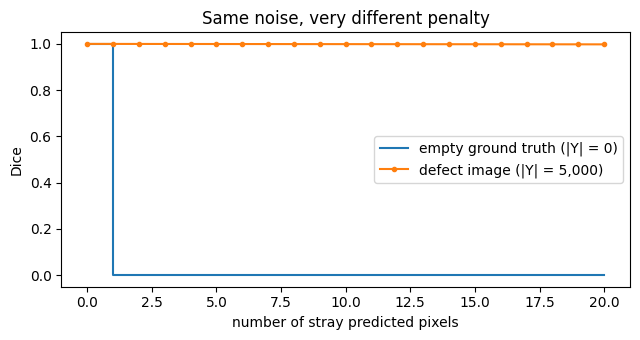

In [18]:
# Same number of stray pixels on a clean image vs on a positive image (|Y| = 5,000, prediction covers it fully)
k = np.arange(0, 21)                                         # stray pixels
dice_empty_gt = dice_empty_aware(0, k, 0)
dice_positive_gt = dice_empty_aware(5000, 5000 + k, 5000)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.step(k, dice_empty_gt, where="post", label="empty ground truth (|Y| = 0)")
ax.plot(k, dice_positive_gt, marker="o", ms=3, label="defect image (|Y| = 5,000)")
ax.set_xlabel("number of stray predicted pixels")
ax.set_ylabel("Dice")
ax.set_title("Same noise, very different penalty")
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation
- A model that correctly predicts nothing receives the full score, while a model that adds a *single* stray pixel receives zero: the penalty is a step, not a slope, and it does not depend on how many pixels are hallucinated.
- On a defect image the same stray pixels are almost free, because the formula divides by thousands of true defect pixels.
---

## Q8. Official Competition Weighted Metric: Toy Batch

**Objective:** evaluate the three components and the final score of the competition metric on a small, fully specified validation batch.

In [19]:
pos_dice = np.array([0.80] * 6 + [0.40] * 4)                  # Dice on the 10 positive pairs
fp_pixels = np.array([0] * 36 + [1024] * 4)                    # predicted pixels on the 40 empty pairs

foreground_dice = pos_dice.mean()
false_positive_score = 1 - (fp_pixels / CANVAS_PIXELS).mean()
empty_accuracy = (fp_pixels == 0).mean()
final_score = 0.70 * foreground_dice + 0.20 * false_positive_score + 0.10 * empty_accuracy

print(f"(a) ForegroundDice       = {foreground_dice:.4f}   (mean over {len(pos_dice)} positive pairs)")
print(f"(b) FalsePositiveScore   = {false_positive_score:.4f}   (mean FP fraction over {len(fp_pixels)} empty pairs)")
print(f"(c) EmptyAccuracy        = {empty_accuracy:.4f}   ({(fp_pixels == 0).sum()} of {len(fp_pixels)} empty pairs predicted empty)")
print(f"(d) Final weighted score = {final_score:.4f}")
print(f"\nQ8 answer: {foreground_dice:.4f}, {false_positive_score:.4f}, {empty_accuracy:.4f}, {final_score:.4f}")

(a) ForegroundDice       = 0.6400   (mean over 10 positive pairs)
(b) FalsePositiveScore   = 0.9990   (mean FP fraction over 40 empty pairs)
(c) EmptyAccuracy        = 0.9000   (36 of 40 empty pairs predicted empty)
(d) Final weighted score = 0.7378

Q8 answer: 0.6400, 0.9990, 0.9000, 0.7378


### Interpretation
- ForegroundDice is averaged over the 10 positive pairs only; averaging over all 50 pairs would mix in the empty pairs and corrupt the term.
- The false-alarm blobs cost very little in FalsePositiveScore (each covers a tiny fraction of the canvas) but they are fully visible in EmptyAccuracy, which counts every non-empty prediction on a clean pair as a failure. The two terms therefore complement each other: one measures how much is hallucinated, the other how often.
- The final score is dominated by the Dice term (weight 0.70), so the model must localise real defects well; avoiding false alarms alone cannot produce a high score.
- The final score is computed from the unrounded components and rounded only at the end.

---

## Q9. The All-Empty Baseline on the Full Training Set

**Objective:** evaluate the trivial "always predict an empty mask" baseline on all 45,572 training image-class pairs, once with naive empty-aware mean Dice and once with the official three-component score, and compare.

In [20]:
def competition_score(inter, pred_area, gt_area, canvas=CANVAS_PIXELS, weights=(0.70, 0.20, 0.10)):
    """Official 3-part score from per-pair pixel counts (intersection, predicted area, ground-truth area)."""
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    positive = gt_area > 0
    empty = ~positive
    dice = dice_empty_aware(inter, pred_area, gt_area)

    fg = dice[positive].mean()
    fp = 1 - (pred_area[empty] / canvas).mean()
    ea = (pred_area[empty] == 0).mean()
    w_fg, w_fp, w_ea = weights
    return {"foreground_dice": fg, "false_positive_score": fp, "empty_accuracy": ea,
            "score": w_fg * fg + w_fp * fp + w_ea * ea}


def rle_area(rle):
    """Number of foreground pixels of an RLE string (0 for empty)."""
    if not isinstance(rle, str) or not rle.strip():
        return 0
    return sum(map(int, rle.split()[1::2]))


gt_area = train.mask_rle.apply(rle_area).to_numpy()
n_pairs = len(train)
n_empty = int((gt_area == 0).sum())
n_positive = n_pairs - n_empty
print(f"Image-class pairs: {n_pairs:,} | empty ground truth: {n_empty:,} | positive: {n_positive:,}")
print(f"Emptiness rate: {n_empty / n_pairs:.4f}")

pred_area = np.zeros(n_pairs)
inter = np.zeros(n_pairs)

naive_mean_dice = dice_empty_aware(inter, pred_area, gt_area).mean()
official = competition_score(inter, pred_area, gt_area)

print(f"\nNaive empty-aware mean Dice : {naive_mean_dice:.4f}")
print("Official components         :", {k: round(float(v), 4) for k, v in official.items() if k != "score"})
print(f"Official competition score  : {official['score']:.4f}")
print(f"\nQ9 answer: {naive_mean_dice:.4f}, {official['score']:.4f}")

Image-class pairs: 45,572 | empty ground truth: 38,371 | positive: 7,201
Emptiness rate: 0.8420

Naive empty-aware mean Dice : 0.8420
Official components         : {'foreground_dice': 0.0, 'false_positive_score': 1.0, 'empty_accuracy': 1.0}
Official competition score  : 0.3000

Q9 answer: 0.8420, 0.3000


In [21]:

empty_by_class = (train.assign(is_empty=(gt_area == 0)).groupby("defect_type").is_empty.mean()).round(4)
display(empty_by_class.rename("fraction_of_images_without_this_defect").to_frame())


shuffled = competition_score(inter, pred_area, np.random.permutation(gt_area))
print("Official score after shuffling the labels:", round(float(shuffled["score"]), 4))

,fraction_of_images_without_this_defect
defect_type,
defect_a,0.9051
defect_b,0.9725
defect_c,0.6401
defect_d,0.8502


Official score after shuffling the labels: 0.3


### Interpretation
- The naive number is just the share of empty pairs, so it looks flattering only because the data is dominated by clean pairs; the baseline detects no defect at all.
- The official score of the same predictions is a constant fixed by the weights: 70% of the score is reserved for a term on which the baseline gets zero. It does not change with the emptiness rate (the shuffle check confirms that the value does not depend on which pairs are empty).
- The two numbers differ widely for exactly the same predictions, which is the **All-Empty Baseline Paradox**: a single aggregate metric can be gamed by a model that abstains.
---

## Q10. Morphological Noise Filtering: Minimum-Area Recall Ceilings

**Objective:** measure the connected-component structure of the ground-truth masks and quantify how much true defect signal a minimum-area filter would destroy.

In [22]:
import cv2

component_areas = {c: [] for c in DEFECT_TYPES}

for defect, rle in zip(positives.defect_type, positives.mask_rle):
    mask = rle_decode(rle)
    _, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    component_areas[defect].extend(stats[1:, cv2.CC_STAT_AREA].tolist())   # row 0 is the background

component_areas = {c: np.array(a) for c, a in component_areas.items()}

summary = pd.DataFrame({
    c: {"components": len(a), "min_area": a.min(), "median_area": int(np.median(a)),
        "max_area": a.max(), "total_pixels": a.sum()}
    for c, a in component_areas.items()
}).T
display(summary)

,components,min_area,median_area,max_area,total_pixels
defect_a,2239,3,239,3846,809388
defect_b,341,93,554,2331,215701
defect_c,9129,1,1081,82170,22787304
defect_d,2796,1,2695,44766,12205494


In [23]:
def pixel_loss_pct(areas, n):
    """Percentage of ground-truth PIXELS lying in components smaller than n."""
    return 100 * areas[areas < n].sum() / areas.sum()


def blob_loss_pct(areas, n):
    """Percentage of ground-truth COMPONENTS (instances) smaller than n."""
    return 100 * (areas < n).mean()


area_min_b = int(component_areas["defect_b"].min())
lost_pct_b_50 = pixel_loss_pct(component_areas["defect_b"], 50)
lost_pct_a_200 = pixel_loss_pct(component_areas["defect_a"], 200)

print(f"(1) smallest defect_b component: {area_min_b} px")
print(f"(2) defect_b pixels discarded at N = 50 : {lost_pct_b_50:.2f}%")
print(f"(3) defect_a pixels discarded at N = 200: {lost_pct_a_200:.2f}%")
print(f"\nQ10 answer: {area_min_b}, {lost_pct_b_50:.2f}, {lost_pct_a_200:.2f}")

(1) smallest defect_b component: 93 px
(2) defect_b pixels discarded at N = 50 : 0.00%
(3) defect_a pixels discarded at N = 200: 15.22%

Q10 answer: 93, 0.00, 15.22


Ground-truth PIXELS lost (%)


,defect_a,defect_b,defect_c,defect_d
N=10,0.00,0.00,0.00,0.01
N=25,0.00,0.00,0.01,0.01
N=50,0.03,0.00,0.04,0.01
N=100,1.22,0.04,0.10,0.02
N=200,15.22,1.34,0.34,0.08
N=500,50.89,23.19,2.31,0.53


Ground-truth COMPONENTS lost (%)


,defect_a,defect_b,defect_c,defect_d
N=10,0.13,0.00,1.35,9.26
N=25,0.13,0.00,2.44,10.41
N=50,0.40,0.00,4.22,10.80
N=100,5.63,0.29,6.25,11.41
N=200,39.04,5.57,10.24,13.05
N=500,81.24,43.11,24.48,18.85


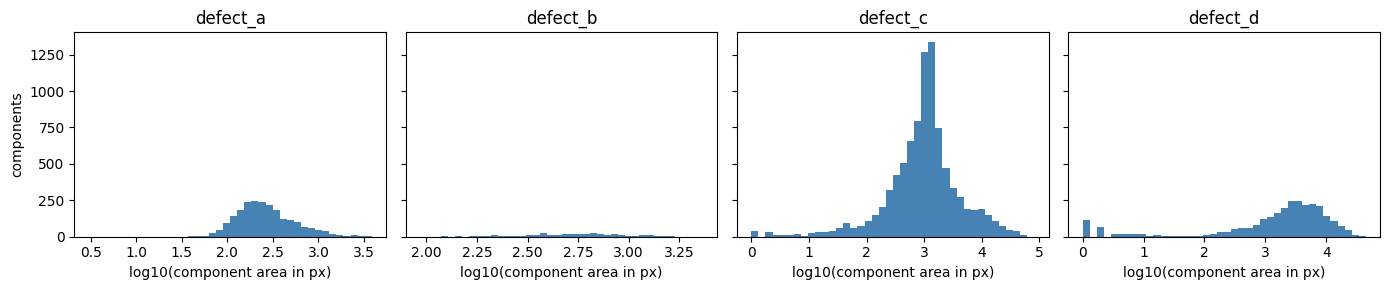

In [24]:
thresholds_n = [10, 25, 50, 100, 200, 500]
pixel_table = pd.DataFrame({c: [pixel_loss_pct(a, n) for n in thresholds_n] for c, a in component_areas.items()},
                           index=[f"N={n}" for n in thresholds_n]).round(2)
blob_table = pd.DataFrame({c: [blob_loss_pct(a, n) for n in thresholds_n] for c, a in component_areas.items()},
                          index=[f"N={n}" for n in thresholds_n]).round(2)
print("Ground-truth PIXELS lost (%)"); display(pixel_table)
print("Ground-truth COMPONENTS lost (%)"); display(blob_table)

fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, (c, a) in zip(axes, component_areas.items()):
    ax.hist(np.log10(a), bins=40, color="steelblue")
    ax.set_title(c); ax.set_xlabel("log10(component area in px)")
axes[0].set_ylabel("components")
plt.tight_layout()
plt.show()

### Interpretation
- Component sizes differ strongly between classes, so a threshold that is harmless for one class can remove a large share of another; the ceiling must be checked **per class** before choosing `N`.
- The pixel loss is much smaller than the share of components removed at the same `N`: tiny components are numerous but carry few pixels. The recall ceiling for a pixel-level Dice follows the *pixel* table, not the blob table.
---

## Q11. Multi-Label Combination Stratification

**Objective:** build a single 80/20 train/validation holdout over the 11,393 training images that preserves rare classes and their co-occurrences, and compute the idealised number of `defect_b` images in the validation set.

In [25]:

combo = (positives.groupby("image_id").defect_type.apply(lambda s: "+".join(sorted(s)))
         .reindex(train.image_id.unique()).fillna("clean"))
combo.name = "combo"

n_combos = combo.nunique()
print(f"Unique combination strings: {n_combos}")

presence_img = (train.pivot(index="image_id", columns="defect_type", values="has_defect")[DEFECT_TYPES]
                .astype(int).reindex(combo.index))
strata = pd.DataFrame({
    "images": combo.value_counts(),
    "defect_b_images": presence_img["defect_b"].groupby(combo).sum(),
}).fillna(0).astype(int).sort_values("images", ascending=False)
strata["ideal_val_images"] = 0.2 * strata.images
strata["ideal_val_defect_b"] = 0.2 * strata.defect_b_images
display(strata.round(2))

ideal_b_in_val = strata.ideal_val_defect_b.sum()
b_in_val = int(np.floor(ideal_b_in_val + 0.5))       
print(f"\nIdeal (fractional) defect_b images in validation: {ideal_b_in_val:.2f}")
print(f"Check: 0.2 x total defect_b images = {0.2 * presence_img['defect_b'].sum():.2f}")
print(f"\nQ11 answer: {n_combos}, {b_in_val}")

Unique combination strings: 15


,images,defect_b_images,ideal_val_images,ideal_val_defect_b
combo,,,,
clean,5516,0,1103.2,0.0
defect_c,3105,0,621.0,0.0
defect_d,822,0,164.4,0.0
defect_a,601,0,120.2,0.0
defect_c+defect_d,598,0,119.6,0.0
defect_a+defect_c,215,0,43.0,0.0
defect_b,151,151,30.2,30.2
defect_a+defect_d,136,0,27.2,0.0
defect_a+defect_c+defect_d,87,0,17.4,0.0



Ideal (fractional) defect_b images in validation: 62.60
Check: 0.2 x total defect_b images = 62.60

Q11 answer: 15, 63


In [26]:

n_val = int(round(0.2 * len(combo)))
p_b = presence_img["defect_b"].mean()
sigma_b = np.sqrt(n_val * p_b * (1 - p_b))
print(f"Random holdout: expected defect_b in validation = {n_val * p_b:.1f}, sigma = {sigma_b:.2f} "
      f"({100 * sigma_b / (n_val * p_b):.1f}% relative); stratified holdout: sigma = 0 by construction")

Random holdout: expected defect_b in validation = 62.6, sigma = 7.80 (12.5% relative); stratified holdout: sigma = 0 by construction


In [27]:
from sklearn.model_selection import train_test_split

assert combo.value_counts().min() >= 2, "a stratum with a single image cannot appear in both partitions"

image_ids = combo.index.to_numpy()
train_ids, val_ids = train_test_split(image_ids, test_size=0.2, random_state=SEED, stratify=combo.values)

holdout = pd.DataFrame({"image_id": image_ids, "combo": combo.values})
holdout["split"] = np.where(holdout.image_id.isin(set(val_ids)), "val", "train")

check = presence_img.join(holdout.set_index("image_id").split).groupby("split")[DEFECT_TYPES].mean().round(4)
check["clean_images"] = (presence_img.sum(axis=1) == 0).groupby(holdout.set_index("image_id").split).mean().round(4)
display(check)
print(f"Images: train = {len(train_ids):,} | validation = {len(val_ids):,}")
print(f"Actual defect_b images in validation: {int(presence_img.loc[val_ids, 'defect_b'].sum())} (ideal {ideal_b_in_val:.2f})")

holdout.to_csv("holdout.csv", index=False)

,defect_a,defect_b,defect_c,defect_d,clean_images
split,,,,,
train,0.0949,0.0274,0.3599,0.1498,0.4842
val,0.0948,0.0276,0.3598,0.1501,0.4840


Images: train = 9,114 | validation = 2,279
Actual defect_b images in validation: 63 (ideal 62.60)


### Interpretation
- There are fewer distinct strata than the 16 theoretically possible combinations (four binary labels), because some combinations never occur; every stratum that does occur has enough images to appear in both partitions.
- Because every stratum is split 20/80, the idealised validation count for any class equals 20% of that class's total, which the check line confirms; the stratified split removes the random fluctuation of the validation support for rare classes and co-occurrences.
- Actual integer allocation rounds each stratum, so the real counts differ from the ideal by a fraction of an image per stratum. The verification table shows that class prevalences are nearly identical in both partitions.
- The split is made on **images**, not on rows, so the four annotation rows of one image can never leak between training and validation. The holdout is saved to `holdout.csv` for reuse in Question 12 and in all later milestones.

---

## Q12. Baseline Segmentation Model and Decision-Threshold Sweep

**Objective:** train a baseline segmentation network on the 80% partition, and study on the stratified 20% holdout how the decision threshold `tau in {0.3, 0.5, 0.7, 0.9}` changes false positives on empty pairs, foreground Dice on positive pairs, and the two summary metrics (naive mean Dice and the official score), with no minimum-area filtering.

In [28]:
%pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 2.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [29]:
import random, time
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import segmentation_models_pytorch as smp

QUICK_RUN = False           
EPOCHS = 8                  
BATCH_SIZE = 16
LEARNING_RATE = 3e-4
ENCODER_WEIGHTS = "imagenet"  
THRESHOLDS = [0.3, 0.5, 0.7, 0.9]
OUT_DIR = Path("/kaggle/working/milestone_1_outputs"); OUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

if QUICK_RUN:
    rng = np.random.default_rng(SEED)
    run_train_ids = rng.choice(train_ids, 320, replace=False)
    run_val_ids = rng.choice(val_ids, 96, replace=False)
    EPOCHS = 1
else:
    run_train_ids, run_val_ids = train_ids, val_ids
print(f"train images: {len(run_train_ids):,} | validation images: {len(run_val_ids):,} | epochs: {EPOCHS}")

device: cuda
train images: 9,114 | validation images: 2,279 | epochs: 8


In [30]:

IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
image_index = {p.stem: p for p in DATA_DIR.rglob("*") if p.suffix.lower() in IMAGE_EXTS}
print(f"image files found: {len(image_index):,}")

rle_table = train.pivot(index="image_id", columns="defect_type", values="mask_rle")[DEFECT_TYPES].fillna("")


class SurfaceDefectDataset(Dataset):
    """Returns (image, masks): image (1, 128, 800) float32, masks (4, 128, 800) float32 in {0, 1}."""

    def __init__(self, image_ids, augment=False):
        self.image_ids = list(image_ids)
        self.augment = augment

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        img = np.asarray(Image.open(image_index[image_id]).convert("L"), dtype=np.float32) / 255.0
        masks = np.stack([rle_decode(rle_table.at[image_id, d]) for d in DEFECT_TYPES]).astype(np.float32)
        if self.augment and random.random() < 0.5:                   # horizontal flip of image and masks together
            img, masks = img[:, ::-1], masks[:, :, ::-1]
        img = (img - 0.5) / 0.5                                      # scale to [-1, 1]
        return torch.from_numpy(np.ascontiguousarray(img))[None], torch.from_numpy(np.ascontiguousarray(masks))


train_loader = DataLoader(SurfaceDefectDataset(run_train_ids, augment=True), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(SurfaceDefectDataset(run_val_ids), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=2, pin_memory=True)

imgs, masks = next(iter(train_loader))
print("batch shapes:", tuple(imgs.shape), tuple(masks.shape), "| image range:", float(imgs.min()), float(imgs.max()))

image files found: 14,393
batch shapes: (16, 1, 128, 800) (16, 4, 128, 800) | image range: -1.0 1.0


In [31]:
model = smp.Unet(encoder_name="resnet34", encoder_weights=ENCODER_WEIGHTS, in_channels=1, classes=4).to(device)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

bce = nn.BCEWithLogitsLoss()


def soft_dice_loss(logits, targets, eps=1e-6):
    """1 - soft Dice, averaged over the positive (image, class) pairs of the batch only."""
    probs = torch.sigmoid(logits)
    inter = (probs * targets).sum(dim=(2, 3))
    denom = probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))
    dice = (2 * inter + eps) / (denom + eps)                      # shape (batch, 4)
    positive = targets.sum(dim=(2, 3)) > 0
    return 1 - dice[positive].mean() if positive.any() else logits.sum() * 0


def criterion(logits, targets):
    return bce(logits, targets) + soft_dice_loss(logits, targets)


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

trainable parameters: 24,430,532


In [32]:
@torch.no_grad()
def evaluate_loss(loader):
    model.eval()
    total = 0.0
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        total += criterion(model(imgs), masks).item() * imgs.size(0)
    return total / len(loader.dataset)


history, best_val = [], float("inf")
for epoch in range(1, EPOCHS + 1):
    model.train()
    start, running = time.time(), 0.0
    for imgs, masks in train_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        loss = criterion(model(imgs), masks)
        loss.backward()
        optimizer.step()
        running += loss.item() * imgs.size(0)

    train_loss = running / len(train_loader.dataset)
    val_loss = evaluate_loss(val_loader)
    history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), OUT_DIR / "best.pt")
    print(f"epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | {time.time() - start:.0f}s")

history = pd.DataFrame(history)
history.to_csv(OUT_DIR / "training_history.csv", index=False)

epoch 1/8 | train loss 0.8621 | val loss 0.6467 | 226s
epoch 2/8 | train loss 0.5971 | val loss 0.5854 | 219s
epoch 3/8 | train loss 0.5473 | val loss 0.5090 | 218s
epoch 4/8 | train loss 0.5220 | val loss 0.5046 | 218s
epoch 5/8 | train loss 0.5071 | val loss 0.5162 | 218s
epoch 6/8 | train loss 0.4883 | val loss 0.4874 | 218s
epoch 7/8 | train loss 0.4822 | val loss 0.4836 | 219s
epoch 8/8 | train loss 0.4691 | val loss 0.4739 | 219s


In [33]:

model.load_state_dict(torch.load(OUT_DIR / "best.pt", map_location=device))
model.eval()

pair_stats = {t: {"inter": [], "pred": []} for t in THRESHOLDS}
gt_counts = []
with torch.no_grad():
    for imgs, masks in val_loader:
        probs = torch.sigmoid(model(imgs.to(device)))
        gt = masks.to(device) > 0.5
        gt_counts.append(gt.sum(dim=(2, 3)).cpu().numpy().ravel())
        for t in THRESHOLDS:
            pred = probs >= t
            pair_stats[t]["inter"].append((pred & gt).sum(dim=(2, 3)).cpu().numpy().ravel())
            pair_stats[t]["pred"].append(pred.sum(dim=(2, 3)).cpu().numpy().ravel())

gt_area_val = np.concatenate(gt_counts)
n_pairs_val = len(gt_area_val)
emptiness_val = (gt_area_val == 0).mean()
print(f"Holdout pairs: {n_pairs_val:,} | empty pairs: {(gt_area_val == 0).sum():,} | emptiness rate: {emptiness_val:.4f}")

rows = []
for t in THRESHOLDS:
    inter = np.concatenate(pair_stats[t]["inter"]); pred = np.concatenate(pair_stats[t]["pred"])
    comp = competition_score(inter, pred, gt_area_val)
    empty = gt_area_val == 0
    rows.append({"tau": t,
                 "fp_pair_rate": (pred[empty] > 0).mean(),
                 "fp_pixel_fraction": (pred[empty] / CANVAS_PIXELS).mean(),
                 "foreground_dice": comp["foreground_dice"],
                 "empty_accuracy": comp["empty_accuracy"],
                 "naive_mean_dice": dice_empty_aware(inter, pred, gt_area_val).mean(),
                 "official_score": comp["score"]})

zeros = np.zeros(n_pairs_val)
base = competition_score(zeros, zeros, gt_area_val)
rows.append({"tau": "all-empty baseline", "fp_pair_rate": 0.0, "fp_pixel_fraction": 0.0,
             "foreground_dice": base["foreground_dice"], "empty_accuracy": 1.0,
             "naive_mean_dice": dice_empty_aware(zeros, zeros, gt_area_val).mean(), "official_score": base["score"]})

sweep = pd.DataFrame(rows).set_index("tau").round(4)
display(sweep)
sweep.to_csv(OUT_DIR / "threshold_sweep.csv")

Holdout pairs: 9,116 | empty pairs: 7,675 | emptiness rate: 0.8419


,fp_pair_rate,fp_pixel_fraction,foreground_dice,empty_accuracy,naive_mean_dice,official_score
tau,,,,,,
0.3,0.5448,0.0064,0.5706,0.4552,0.4735,0.6437
0.5,0.5161,0.0056,0.5682,0.4839,0.4972,0.6450
0.7,0.4807,0.0048,0.5636,0.5193,0.5263,0.6455
0.9,0.4124,0.0033,0.5452,0.5876,0.5809,0.6397
all-empty baseline,0.0000,0.0000,0.0000,1.0000,0.8419,0.3000


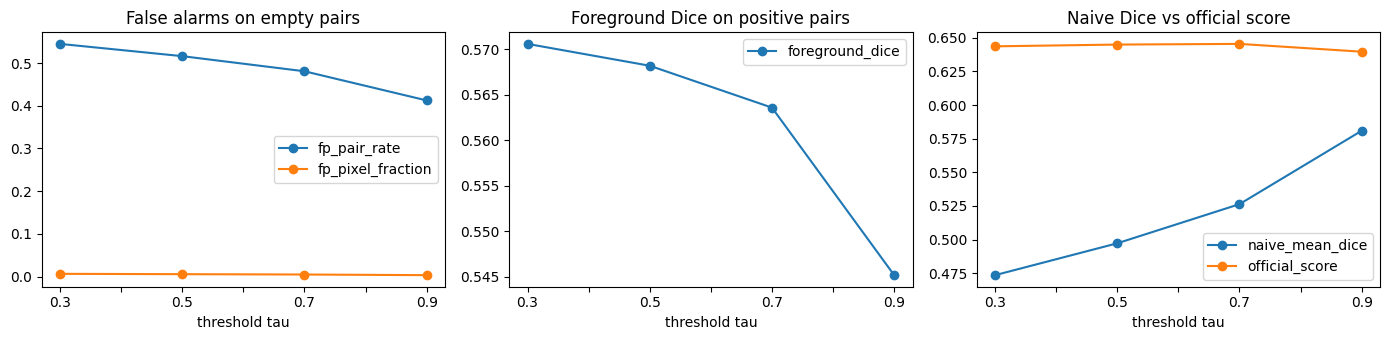

False-positive pair rate by tau : {0.3: 0.5448, 0.5: 0.5161, 0.7: 0.4807, 0.9: 0.4124}
Foreground Dice by tau          : {0.3: 0.5706, 0.5: 0.5682, 0.7: 0.5636, 0.9: 0.5452}
Naive mean Dice peaks at tau = 0.9  (0.5809)
Official score peaks at tau = 0.7  (0.6455)
All-empty baseline on this holdout: naive = 0.8419, official = 0.3


In [34]:
sw = sweep.loc[THRESHOLDS].astype(float)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
sw[["fp_pair_rate", "fp_pixel_fraction"]].plot(ax=ax[0], marker="o"); ax[0].set_title("False alarms on empty pairs")
sw[["foreground_dice"]].plot(ax=ax[1], marker="o"); ax[1].set_title("Foreground Dice on positive pairs")
sw[["naive_mean_dice", "official_score"]].plot(ax=ax[2], marker="o"); ax[2].set_title("Naive Dice vs official score")
for a in ax:
    a.set_xlabel("threshold tau")
plt.tight_layout()
plt.savefig(OUT_DIR / "threshold_sweep.png", dpi=120)
plt.show()

print("False-positive pair rate by tau :", sw.fp_pair_rate.round(4).to_dict())
print("Foreground Dice by tau          :", sw.foreground_dice.round(4).to_dict())
print(f"Naive mean Dice peaks at tau = {sw.naive_mean_dice.idxmax()}  ({sw.naive_mean_dice.max():.4f})")
print(f"Official score peaks at tau = {sw.official_score.idxmax()}  ({sw.official_score.max():.4f})")
print(f"All-empty baseline on this holdout: naive = {sweep.loc['all-empty baseline', 'naive_mean_dice']}, "
      f"official = {sweep.loc['all-empty baseline', 'official_score']}")